In [1584]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

In [1585]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

In [1586]:
from keras.models import Sequential

In [1587]:
from keras.layers import Dense
from keras.layers import LSTM

In [1588]:
#df_vitals = pd.read_csv('vitals2_lstm.csv')
#df_vitals = pd.read_csv('combined_vitals.csv')
df_vitals = pd.read_csv('vitals_combined_interpolated.csv')

In [1589]:
df_vitals.head()

,patient_uuid,reading_date,batch,HR,SBP
0,1127912,2019-11-19,0,87.261064,124.85394
1,1127912,2019-11-20,0,92.000000,120.50000
2,1127912,2019-11-21,0,87.000000,131.75000
3,1127912,2019-11-22,0,89.000000,127.00000
4,1127912,2019-11-23,0,93.000000,109.50000


In [1590]:
df_vitals.rename(columns = {'reading_date':'timestamp'}, inplace = True)
df_vitals['timestamp'] = pd.to_datetime(df_vitals['timestamp'], errors='coerce')
df_vitals

,patient_uuid,timestamp,batch,HR,SBP
0,1127912,2019-11-19,0,87.261064,124.853940
1,1127912,2019-11-20,0,92.000000,120.500000
2,1127912,2019-11-21,0,87.000000,131.750000
3,1127912,2019-11-22,0,89.000000,127.000000
4,1127912,2019-11-23,0,93.000000,109.500000
...,...,...,...,...,...
127630,99814066,2020-01-08,0,97.283923,112.820825
127631,99814066,2020-01-09,0,93.460395,110.853570
127632,99814066,2020-01-10,0,89.636867,108.886316
127633,99814066,2020-01-11,0,85.813338,106.919062


In [1591]:
# Drops batches containing less than 30 observations.
df_recordings_per_patient = df_vitals.groupby(['patient_uuid', 'batch']).count().reset_index()
low_batches = df_recordings_per_patient[(df_recordings_per_patient.HR <= 30)][['patient_uuid','batch']]
for i in range(len(low_batches)):
    low_patient = low_batches.patient_uuid.iloc[i]
    low_batch = low_batches.batch.iloc[i]
    df_vitals.drop(df_vitals[(df_vitals.patient_uuid == low_patient) & (df_vitals.batch == low_batch)].index, inplace=True)

In [1592]:
#df_vitals['reading_date'] = pd.to_datetime(df_vitals['reading_date'],errors='coerce')
df_vitals.head()

,patient_uuid,timestamp,batch,HR,SBP
0,1127912,2019-11-19,0,87.261064,124.85394
1,1127912,2019-11-20,0,92.000000,120.50000
2,1127912,2019-11-21,0,87.000000,131.75000
3,1127912,2019-11-22,0,89.000000,127.00000
4,1127912,2019-11-23,0,93.000000,109.50000


In [1593]:
#df_vitals=df_vitals[(df_vitals.timestamp>'2018-10-01')] # &(df_vitals.timestamp<'2019-11-11')
df_vitals=df_vitals[(df_vitals.timestamp >= '2018-10-01') & (df_vitals.timestamp <= '2020-01-14')]
# remove all na entries
#df_vitals=df_vitals[~df_vitals['DBP'].isna()]
#df_vitals=df_vitals[~df_vitals['SBP'].isna()]
#df_vitals=df_vitals[~df_vitals['HR'].isna()]

In [1594]:
print(df_vitals.count())

patient_uuid    121156
timestamp       121156
batch           121156
HR              121156
SBP             121156
dtype: int64


In [1595]:
#df_vitals.to_csv('df_vitals_combined_int.csv', encoding='utf-8')

In [1596]:
# Systolic Blood Pressure. 
df_vitals_sbp = df_vitals[['timestamp','patient_uuid','SBP']] # 'SBP' 'DBP'
df_vitals_sbp

,timestamp,patient_uuid,SBP
0,2019-11-19,1127912,124.853940
1,2019-11-20,1127912,120.500000
2,2019-11-21,1127912,131.750000
3,2019-11-22,1127912,127.000000
4,2019-11-23,1127912,109.500000
...,...,...,...
127625,2019-03-18,99726731,130.000000
127626,2019-03-19,99726731,115.000000
127627,2019-03-20,99726731,116.368667
127628,2019-03-21,99726731,147.000000


In [1597]:
# Also, Heart rate. 
df_vitals_hr = df_vitals[['timestamp','patient_uuid','HR']] # 'SBP' 'DBP'
df_vitals_hr

,timestamp,patient_uuid,HR
0,2019-11-19,1127912,87.261064
1,2019-11-20,1127912,92.000000
2,2019-11-21,1127912,87.000000
3,2019-11-22,1127912,89.000000
4,2019-11-23,1127912,93.000000
...,...,...,...
127625,2019-03-18,99726731,60.000000
127626,2019-03-19,99726731,59.000000
127627,2019-03-20,99726731,65.526797
127628,2019-03-21,99726731,56.000000


In [1598]:
patients = df_vitals.patient_uuid.unique()#df_vitals_sbp.patient_uuid.unique()
patientsS = patients[5:9]
patientsS

array([1519674, 1523219, 2075791, 2096100])

In [1599]:
#df_select_uuid = df_vitals_sbp # 
df_select_uuid = df_vitals_sbp.loc[df_vitals_sbp['patient_uuid'] == 73939445] #1519674 #8989080 # 82591262 # 54404566 # 73939445 # 9448847

In [1600]:
df_select_uuid.head()

,timestamp,patient_uuid,SBP
95713,2019-04-29,73939445,193.250000
95714,2019-04-30,73939445,167.333333
95715,2019-05-01,73939445,158.500000
95716,2019-05-02,73939445,181.500000
95717,2019-05-03,73939445,159.000000


In [1601]:
df_SBP = df_select_uuid[['SBP']]

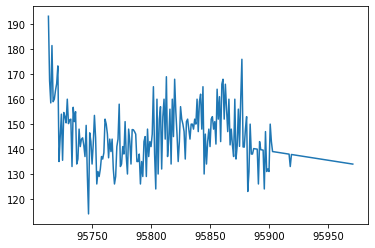

In [1602]:
plt.plot(df_SBP)
plt.show()

In [1603]:
# fix random seed for reproducibility
np.random.seed(7)

In [1604]:
dataset = df_SBP.astype('float32')
dataset

,SBP
95713,193.250000
95714,167.333328
95715,158.500000
95716,181.500000
95717,159.000000
...,...
95967,134.271408
95968,134.197433
95969,134.123459
95970,134.049484


In [1605]:
# normalize the dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

In [1606]:
# split into train and test sets
train_size = len(dataset) - 7
test_size = 7#len(dataset) - train_size
train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]
print(len(train), len(test))

252 7


In [1607]:
# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1):
	dataX, dataY = [], []
	for i in range(len(dataset)-look_back-1):
		a = dataset[i:(i+look_back), 0]
		dataX.append(a)
		dataY.append(dataset[i + look_back, 0])
	return np.array(dataX), np.array(dataY)

In [1608]:
# reshape into X=t and Y=t+1
look_back = 3 # 1 look_back must be < 7
trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

In [1609]:
# reshape input to be [samples, time steps, features]
#trainX = np.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1])) #no time steps
#testX = np.reshape(testX, (testX.shape[0], 1, testX.shape[1]))     #no time steps

trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1)) 
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

In [1610]:
# create and fit the LSTM network
batch_size = 1
model = Sequential()
#model.add(LSTM(4, batch_input_shape=(batch_size, look_back, 1), stateful=True)) #time steps, memory between batches
model.add(LSTM(4, input_shape=(look_back, 1))) #time steps, no memory
# model.add(LSTM(4, input_shape=(1, look_back))) #no time steps, no memory
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])

#for i in range(3): # range(100)
#	model.fit(trainX, trainY, epochs=1, batch_size=batch_size, verbose=2, shuffle=False)
#	model.reset_states()

model.fit(trainX, trainY, epochs=30, batch_size=1, verbose=2) # epochs=10, epochs=100, epochs=30, epochs=3,

Epoch 1/30
 - 1s - loss: 0.0305 - mae: 0.1323
Epoch 2/30
 - 1s - loss: 0.0134 - mae: 0.0906
Epoch 3/30
 - 1s - loss: 0.0135 - mae: 0.0884
Epoch 4/30
 - 0s - loss: 0.0133 - mae: 0.0890
Epoch 5/30
 - 0s - loss: 0.0132 - mae: 0.0880
Epoch 6/30
 - 0s - loss: 0.0131 - mae: 0.0872
Epoch 7/30
 - 0s - loss: 0.0129 - mae: 0.0862
Epoch 8/30
 - 0s - loss: 0.0129 - mae: 0.0841
Epoch 9/30
 - 0s - loss: 0.0129 - mae: 0.0862
Epoch 10/30
 - 0s - loss: 0.0130 - mae: 0.0876
Epoch 11/30
 - 1s - loss: 0.0128 - mae: 0.0859
Epoch 12/30
 - 0s - loss: 0.0127 - mae: 0.0851
Epoch 13/30
 - 0s - loss: 0.0127 - mae: 0.0844
Epoch 14/30
 - 0s - loss: 0.0127 - mae: 0.0840
Epoch 15/30
 - 0s - loss: 0.0126 - mae: 0.0833
Epoch 16/30
 - 0s - loss: 0.0128 - mae: 0.0852
Epoch 17/30
 - 0s - loss: 0.0126 - mae: 0.0837
Epoch 18/30
 - 0s - loss: 0.0126 - mae: 0.0844
Epoch 19/30
 - 0s - loss: 0.0126 - mae: 0.0843
Epoch 20/30
 - 0s - loss: 0.0124 - mae: 0.0831
Epoch 21/30
 - 0s - loss: 0.0127 - mae: 0.0829
Epoch 22/30
 - 0s - lo

In [1611]:
# make predictions
#trainPredict = model.predict(trainX, batch_size=batch_size) #memory between batches
trainPredict = model.predict(trainX) # no memory
#model.reset_states() #memory between batches
#testPredict = model.predict(testX, batch_size=batch_size) #memory between bathes
testPredict = model.predict(testX) # no memory

# invert predictions
trainPredict = scaler.inverse_transform(trainPredict)
trainY = scaler.inverse_transform([trainY])
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform([testY])

# calculate root mean squared error
trainScore = np.sqrt(mean_squared_error(trainY[0], trainPredict[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = np.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
print('Test Score: %.2f RMSE' % (testScore))

Train Score: 8.76 RMSE
Test Score: 3.04 RMSE


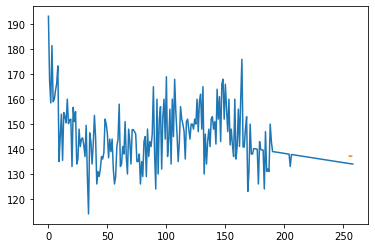

In [1612]:
# shift train predictions for plotting
#trainPredictPlot = np.empty_like(dataset)
#trainPredictPlot[:, :] = np.nan
#trainPredictPlot[look_back:len(trainPredict)+look_back, :] = trainPredict

# shift test predictions for plotting
testPredictPlot = np.empty_like(dataset)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(trainPredict)+(look_back*2)+1:len(dataset)-1, :] = testPredict

# plot baseline and predictions
plt.plot(scaler.inverse_transform(dataset))

#plt.plot(dataset)
#plt.plot(trainPredictPlot)
plt.plot(testPredictPlot)
plt.show()

In [1613]:
# Select UUID
df_select_uuid = df_vitals_sbp.loc[df_vitals_sbp['patient_uuid'] == 73939445] #1519674 #8989080 # 82591262 # 54404566 # 73939445 # 9448847

In [1614]:
# fix random seed for reproducibility
np.random.seed(7)
epoch_count = 3

# Select SBP
df_SBP = df_select_uuid[['SBP']]
dataset = df_SBP.astype('float32')

# normalize the dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

# split into train and test sets
train_size = len(dataset) - 7
test_size = 7#len(dataset) - train_size
train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]
print('Patient: ', df_select_uuid.iloc[0]['patient_uuid'], 'Train: ', len(train), 'Test: ', len(test))

# reshape into X=t and Y=t+1
look_back = 3 # 1 look_back must be < 7
trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1)) 
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

# create and fit the LSTM network
batch_size = 1
model = Sequential()
model.add(LSTM(4, input_shape=(look_back, 1))) #time steps, no memory
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])
history = model.fit(trainX, trainY, epochs=epoch_count, batch_size=1, verbose=0) # epochs=10, epochs=100, epochs=30, epochs=3,

# make predictions
testPredict = model.predict(testX) # no memory

# invert predictions
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform([testY])

# calculate root mean squared error
print('Train Score: %.2f RMSE' % (trainScore))
testScore = np.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
print('Test Score: %.2f RMSE' % (testScore))
print('MAPE: %2f ' % history.history['mae'][epoch_count-1])

Patient:  73939445 Train:  252 Test:  7
Train Score: 8.76 RMSE
Test Score: 6.65 RMSE
MAPE: 0.093723 


In [1615]:
def split_sequence(sequence, n_steps_in, n_steps_out):
	X, y = list(), list()
	for i in range(len(sequence)):
		# find the end of this pattern
		end_ix = i + n_steps_in
		out_end_ix = end_ix + n_steps_out
		# check if we are beyond the sequence
		if out_end_ix > len(sequence):
			break
		# gather input and output parts of the pattern
		seq_x, seq_y = sequence[i:end_ix], sequence[end_ix:out_end_ix]
		X.append(seq_x)
		y.append(seq_y)
	return array(X), array(y)


In [1616]:
def lstm_model(dataset):
    # split a univariate sequence into samples
    #ts = dataset.timestamp.values
    tsData = dataset.copy(deep=True)
    dataset.drop(columns=['timestamp'], inplace=True)
    scaler = MinMaxScaler(feature_range=(0, 1))
    dataset = scaler.fit_transform(dataset)
    
    #dataset['timestamp'] = tsData
    
    train_size = len(dataset) - 7
    test_size = 7 
    train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]
    
    train_result = tsData[0:train_size]
    test_result = tsData[train_size:len(tsData)]
    
    #train_result = scaler.inverse_transform(train) 
    #test_result = scaler.inverse_transform(test)#train2 = train.assign(timestamp = tsData)
    #test2 = test.assign(timestamp = tsData)
    
    #print(dataset[0][:])
    
    # choose a number of time steps
    n_steps_in = 7
    n_steps_out = 7

    # split into samples
    templist = []
    for i in range(len(train)):
        templist.append(train[i][0])

    X, y = split_sequence(templist, n_steps_in, n_steps_out)
    #print('X: ', X)
    #print('test: ', test)    
    
    templist2 = []
    for j in range(len(test)):
        templist2.append(test[j][0])
    testX, testy = split_sequence(templist2, n_steps_in, n_steps_out)
    #print('templist2: ', templist2) 
    #print('testX: ', testX)    
    #print('testy: ', testy)    
    # reshape from [samples, timesteps] into [samples, timesteps, features]
    n_features = 1
    X = X.reshape((X.shape[0], X.shape[1], n_features))
    ##testX = testX.reshape((testX.shape[0], testX.shape[1], n_features))

    # define model
    model = Sequential()
    model.add(LSTM(100, activation='relu', return_sequences=True, input_shape=(n_steps_in, n_features)))
    model.add(LSTM(100, activation='relu'))
    model.add(Dense(n_steps_out))
    model.compile(optimizer='adam', loss='mse')

    # fit model
    model.fit(X, y, epochs=50, verbose=0)

    # Evaluate vs. test
    testX = test.reshape((1, n_steps_in, n_features))
    testPredict = model.predict(testX) # no memory
    
    # Make prediction of future
    x_input = dataset[len(dataset)-n_steps_in:len(dataset),:] #must be n_steps_in long

    #print('x_input: ',x_input)
    x_input = x_input.reshape((1, n_steps_in, n_features))
    #print('x_input after reshape: ',x_input)
    yhat = model.predict(x_input, verbose=0)
    #print('yhat: ',yhat)
    
    #x = np.array([1,2,3,4,5,6,8])
    
    predictions = scaler.inverse_transform(testPredict)

    #l2 = predictions[0].tolist()
    #print(predictions)
    #print(predictions.tolist())
    #print(len(predictions.tolist()))
    #predData = {'timestamp':[tsData[train_size:len(tsData)]], 
    #             tsData.columns[1]:[1,2,3,4,5,6,7]} # predictions.tolist()
    predData = {'timestamp':tsData[train_size:len(tsData)]['timestamp'].tolist(), 
        tsData.columns[1]:predictions[0].tolist()} # predictions.tolist() [1,2,3,4,5,6,7]
    testPredict_result = pd.DataFrame(predData)
        #testPredict_result = pd.DataFrame(columns=['timestamp',tsData.columns[1]])
    
    ts = tsData['timestamp'][len(tsData)-1:len(tsData)]
    dr = pd.date_range(ts.values[0]+ pd.Timedelta('1 day'), periods=7, freq='D')
    futures = scaler.inverse_transform(yhat)    
    futData = {'timestamp':dr, 
        tsData.columns[1]:futures[0].tolist()} # futures.tolist()
    yhat_result = pd.DataFrame(futData)
    #yhat_result = yhat_result.assign()
    
    return train_result, test_result, testPredict_result, yhat_result

In [1652]:
df_select_uuid = df_vitals_sbp.loc[df_vitals_sbp['patient_uuid'] == 1523219] #1127912 73939445 1164638
df_select_uuid_hr = df_vitals_hr.loc[df_vitals_hr['patient_uuid'] == 1523219]
df_SBP = df_select_uuid[['timestamp','SBP']]
#df_HR = df_select_uuid_hr[['HR']]
#df_SBP = df_select_uuid[['timestamp','SBP']]
df_HR = df_select_uuid_hr[['timestamp','HR']]
#df_SBP.head()
#df_HR.head()
#df_HR.iloc[ : , 1 ]

In [1653]:
tr, te, tP, yh = lstm_model(df_SBP)

In [1654]:
trHR, teHR, tPHR, yhHR = lstm_model(df_HR)

In [1655]:
trHR.tail()

,timestamp,HR
641,2019-04-07,70.357641
642,2019-04-08,70.549535
643,2019-04-09,70.741429
644,2019-04-10,70.933324
645,2019-04-11,71.125218


In [1656]:
tr.tail()

,timestamp,SBP
641,2019-04-07,141.442718
642,2019-04-08,141.019124
643,2019-04-09,140.595531
644,2019-04-10,140.171937
645,2019-04-11,139.748343


In [1657]:
teHR.tail()

,timestamp,HR
648,2019-04-14,71.700901
649,2019-04-15,71.892795
650,2019-04-16,70.333333
651,2019-04-17,72.276584
652,2019-04-18,72.468478


In [1658]:
te.tail()

,timestamp,SBP
648,2019-04-14,138.477562
649,2019-04-15,138.053969
650,2019-04-16,139.333333
651,2019-04-17,137.206781
652,2019-04-18,136.783188


In [1659]:
tPHR.tail()

,timestamp,HR
2,2019-04-14,70.633522
3,2019-04-15,70.784958
4,2019-04-16,70.945862
5,2019-04-17,70.939163
6,2019-04-18,70.555656


In [1660]:
tP.tail()

,timestamp,SBP
2,2019-04-14,135.928528
3,2019-04-15,134.900940
4,2019-04-16,134.767105
5,2019-04-17,138.201736
6,2019-04-18,135.046173


In [1661]:
yhHR.tail()

,timestamp,HR
2,2019-04-21,70.633522
3,2019-04-22,70.784958
4,2019-04-23,70.945862
5,2019-04-24,70.939163
6,2019-04-25,70.555656


In [1662]:
yh.tail()

,timestamp,SBP
2,2019-04-21,135.928528
3,2019-04-22,134.900940
4,2019-04-23,134.767105
5,2019-04-24,138.201736
6,2019-04-25,135.046173


In [1663]:
tr = tr.assign(HR=trHR.loc[:, ['HR']])
tr

,timestamp,SBP,HR
604,2019-03-01,144.000000,69.000000
605,2019-03-02,156.692089,63.449447
606,2019-03-03,156.268496,63.641341
607,2019-03-04,175.000000,65.000000
608,2019-03-05,172.000000,64.000000
609,2019-03-06,151.500000,57.500000
610,2019-03-07,151.000000,59.000000
611,2019-03-08,159.500000,61.000000
612,2019-03-09,157.000000,59.000000
613,2019-03-10,152.000000,64.000000


In [1664]:
te = te.assign(HR=teHR.loc[:, ['HR']])
te

,timestamp,SBP,HR
646,2019-04-12,139.324750,71.317112
647,2019-04-13,138.901156,71.509007
648,2019-04-14,138.477562,71.700901
649,2019-04-15,138.053969,71.892795
650,2019-04-16,139.333333,70.333333
651,2019-04-17,137.206781,72.276584
652,2019-04-18,136.783188,72.468478


In [1665]:
tP = tP.assign(HR=tPHR.loc[:, ['HR']])
tP

,timestamp,SBP,HR
0,2019-04-12,135.354828,69.449310
1,2019-04-13,138.008286,67.953178
2,2019-04-14,135.928528,70.633522
3,2019-04-15,134.900940,70.784958
4,2019-04-16,134.767105,70.945862
5,2019-04-17,138.201736,70.939163
6,2019-04-18,135.046173,70.555656


In [1720]:
yh = yh.assign(HR=yhHR.loc[:, ['HR']])
yh

,timestamp,SBP,HR
0,2019-04-19,135.354828,69.449310
1,2019-04-20,138.008286,67.953178
2,2019-04-21,135.928528,70.633522
3,2019-04-22,134.900940,70.784958
4,2019-04-23,134.767105,70.945862
5,2019-04-24,138.201736,70.939163
6,2019-04-25,135.046173,70.555656


In [ ]:
pd.set_option('mode.chained_assignment', None)

# Runs LSTM model on all patients and collects data on accuracy.
HR_mape = []
HR_mae = []
HR_rsme = []
SBP_mape = []
SBP_mae = []
SBP_rsme = []
i = 0

#patientsS = patients[0:8]
#print('patient: ',patientsS)

for patient in patients: #patientsS for a subset    
    print('patient ', i, ': ', patient)
    
    df_select_uuid = df_vitals.loc[df_vitals['patient_uuid'] == patient]
    df_SBP = df_select_uuid[['timestamp','SBP']]
    df_HR = df_select_uuid[['timestamp','HR']]    
    
    results_trainS, results_testS, results_forecastS, results_futureS = lstm_model(df_SBP)
    results_trainH, results_testH, results_forecastH, results_futureH = lstm_model(df_HR)
    
    results_train = pd.DataFrame()
    results_train['timestamp'] = results_trainS['timestamp'].values
    results_train['SBP'] = results_trainS['SBP'].values
    results_train['HR'] = results_trainH['HR'].values
    
    results_test = pd.DataFrame()
    results_test['timestamp'] = results_testS['timestamp'].values
    results_test['SBP'] = results_testS['SBP'].values
    results_test['HR'] = results_testH['HR'].values

    results_forecast = pd.DataFrame()
    results_forecast['timestamp'] = results_forecastS['timestamp'].values
    results_forecast['SBP'] = results_forecastS['SBP'].values
    results_forecast['HR'] = results_forecastH['HR'].values
    
    results_future = pd.DataFrame()
    results_future['timestamp'] = results_futureS['SBP'].values
    results_future['SBP'] = results_futureS['SBP'].values
    results_future['HR'] = results_futureH['HR'].values
    
    i = i + 1    
    
    #print(patient, ' results_forecast: ', results_forecast.head())
    #print(patient, ' results_test: ', results_test.head())
    
    accuracy_indicators = forecast_accuracy(results_forecast, results_test)
    HR_mape.append(accuracy_indicators[0][0])
    HR_mae.append(accuracy_indicators[1][0])
    HR_rsme.append(accuracy_indicators[2][0])
    SBP_mape.append(accuracy_indicators[0][1])
    SBP_mae.append(accuracy_indicators[1][1])
    SBP_rsme.append(accuracy_indicators[2][1])


patient  0 :  1127912
patient  1 :  1164638
patient  2 :  1166047
patient  3 :  1193821
patient  4 :  1231804
patient  5 :  1519674
patient  6 :  1523219
patient  7 :  2075791
patient  8 :  2096100
patient  9 :  2104097
patient  10 :  2132729
patient  11 :  2168037
patient  12 :  2172350
patient  13 :  2469101
patient  14 :  2714491
patient  15 :  2781252
patient  16 :  2793778
patient  17 :  2802493
patient  18 :  2823949
patient  19 :  3005945


In [ ]:
# Creates and populates dataframe containing data on accuracy of the models for each patient.
df_model = pd.DataFrame(columns = ['patient_uuid', 'HR_mape', 'HR_mae', 'HR_rsme', 'SBP_mape', 'SBP_mae', 'SBP_rsme'])
df_model.patient_uuid = patientsS
df_model.HR_mape = HR_mape
df_model.HR_mae = HR_mae
df_model.HR_rsme = HR_rsme
df_model.SBP_mape = SBP_mape
df_model.SBP_mae = SBP_mae
df_model.SBP_rsme = SBP_rsme

df_model.head()

In [ ]:
def forecast_accuracy(forecast, actual):
    """
     Calculates accuracy by calculating mean absolute percentage error, mean absolute error, 
     and root-mean-squared error.
    
    forecast: forecast dataframe containing the results from a model.
    actual  : test set of a particular patient, with same dates as the forecast dataframe.
    
    output  : mape: mean absolute percentage error
              mae : mean absolute error
              rsme: root mean square error
    """
    #forecast = forecast.values
    
    forecast = forecast.set_index('timestamp')
    actual = actual.set_index('timestamp')
    
    mape = np.mean(np.abs(forecast - actual)/np.abs(actual))  # MAPE
    mae = np.mean(np.abs(forecast - actual))    # MAE
    rmse = np.mean((forecast - actual)**2)**.5  # RMSE
    return mape, mae, rmse

In [ ]:
patientsS

In [ ]:
def lstm_model2(dataset):
    # split a univariate sequence into samples
 
    scaler = MinMaxScaler(feature_range=(0, 1))
    dataset = scaler.fit_transform(dataset)
    train_size = len(dataset) - 7
    test_size = 7 
    train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]

    # choose a number of time steps
    n_steps_in = 7
    n_steps_out = 7

    # split into samples
    templist = []
    for i in range(len(train)):
        templist.append(train[i][0])

    X, y = split_sequence(templist, n_steps_in, n_steps_out)
    #print('X: ', X)
    print('test: ', test)    
    
    templist2 = []
    for j in range(len(test)):
        templist2.append(test[j][0])
    testX, testy = split_sequence(templist2, n_steps_in, n_steps_out)
    print('templist2: ', templist2) 
    print('testX: ', testX)    
    print('testy: ', testy)    
    # reshape from [samples, timesteps] into [samples, timesteps, features]
    n_features = 1
    X = X.reshape((X.shape[0], X.shape[1], n_features))
    ##testX = testX.reshape((testX.shape[0], testX.shape[1], n_features))

    # define model
    model = Sequential()
    model.add(LSTM(100, activation='relu', return_sequences=True, input_shape=(n_steps_in, n_features)))
    model.add(LSTM(100, activation='relu'))
    model.add(Dense(n_steps_out))
    model.compile(optimizer='adam', loss='mse')

    # fit model
    model.fit(X, y, epochs=50, verbose=0)

    # Evaluate vs. test
    testX = test.reshape((1, n_steps_in, n_features))
    testPredict = model.predict(testX) # no memory
    
    # Make prediction of future
    x_input = dataset[len(dataset)-n_steps_in:len(dataset),:] #must be n_steps_in long

    print('x_input: ',x_input)
    x_input = x_input.reshape((1, n_steps_in, n_features))
    print('x_input after reshape: ',x_input)
    yhat = model.predict(x_input, verbose=0)
    print('yhat: ',yhat)
    
    train_result = scaler.inverse_transform(train) 
    test_result = scaler.inverse_transform(test)
    testPredict_result = scaler.inverse_transform(testPredict)
    yhat_result = scaler.inverse_transform(yhat)
    
    return train_result, test_result, testPredict_result, yhat_result